# Tutorial 02 — Breaking the Memory Wall: Fitting 300 GB RAM & 80 GB A100 BCI Pipelines onto a 16 GB Consumer GPU
*Language: **English** | [中文版 (Chinese Version)](zh/02_memory_wall_autopsy_16gb_gpu_zh.ipynb)*

Why do most students struggle to run open-source intracortical BCI repositories even when the authors release both code and Dryad datasets?
Because upstream training and decoding scripts are engineered for datacenter servers (**300–512 GB host RAM + 80 GB A100 or multi-GPU RTX 3090/A6000 rigs**). Running them unmodified on a student desktop or gaming laptop immediately hits two **Memory Walls**:

1. **Host RAM Wall (56–300 GB)**:
   - Unpruned 125,000-word Kaldi 5-gram `TLG.fst` weighted finite-state transducers consume **64–300 GB of resident RAM** when eagerly loaded into memory.
   - Eager `np.concatenate` assembly of synthetic handwriting folds (Willett 2021 Step 3) spikes to **56 GB RAM**.
2. **GPU VRAM & cuDNN Wall (40–80 GB)**:
   - Multi-session GRU backbones with per-session `768×768` day-specific input layers overflow VRAM in FP32;
   - PyTorch's monolithic `nn.GRU(num_layers=5, dropout=0.6)` falls off the cuDNN fast path on Windows CUDA (9× slower) and differs from Keras variational dropout;
   - Keeping a 6.7B–8B LLM rescorer resident alongside the acoustic trainer overflows 16 GB VRAM.

In this notebook, we run live benchmarks on your machine to demonstrate the four engineering mitigations used across this suite.

In [1]:
from pathlib import Path
import time
import tempfile
import yaml
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "reproduction_benchmark.yaml").exists())
with open(REPO_ROOT / "reproduction_benchmark.yaml", encoding="utf-8") as f:
    bench = yaml.safe_load(f)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active compute device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))

Active compute device: cuda (NVIDIA GeForce RTX 5060 Ti)


## 1. Visual Comparison: Official Hardware Requirements vs. Our Consumer-PC Peaks

Let's plot Panels (g) and (h) from `reproduction_benchmark.yaml`, comparing official peak RAM and GPU VRAM against our consumer-PC reproduction under the **64 GB DDR5 RAM** and **16 GB RTX 5060 Ti VRAM** ceilings:

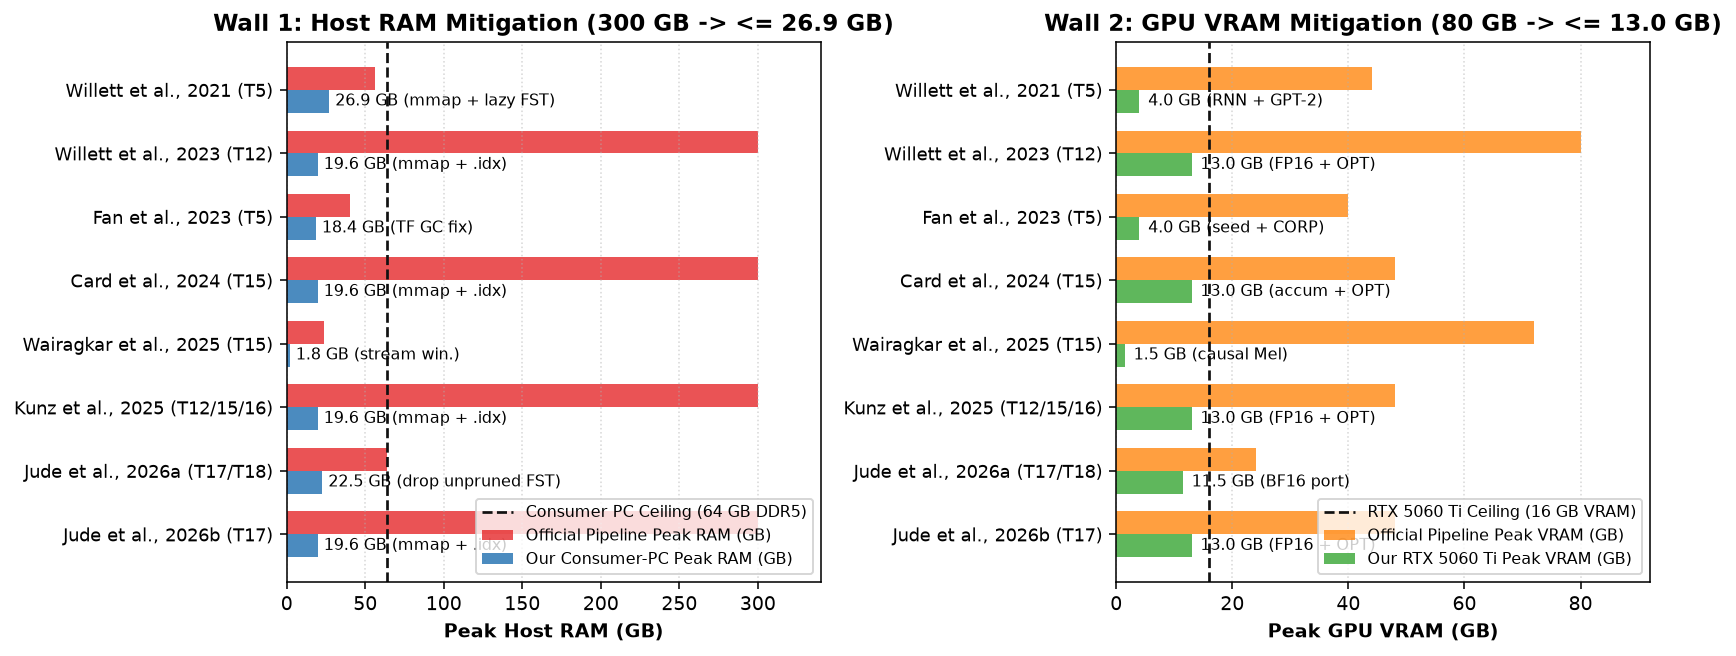

In [2]:
ram_items = bench["panel_g_host_ram_walls"]
vram_items = bench["panel_h_gpu_vram_walls"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# Left: Host RAM
labels_ram = [x["category"] for x in ram_items]
off_ram = [x["official_gb"] for x in ram_items]
our_ram = [x["ours_gb"] for x in ram_items]
y = np.arange(len(labels_ram))
h = 0.36

ax1.barh(y - h/2, off_ram, h, color="#e41a1c", alpha=0.75, label="Official Pipeline Peak RAM (GB)")
ax1.barh(y + h/2, our_ram, h, color="#377eb8", alpha=0.90, label="Our Consumer-PC Peak RAM (GB)")
ax1.axvline(64.0, color="#111111", ls="--", lw=1.4, label="Consumer PC Ceiling (64 GB DDR5)")
for i, item in enumerate(ram_items):
    ax1.text(our_ram[i] + 4, y[i] + h/2, f"{our_ram[i]} GB ({item['note']})", va="center", fontsize=8)
ax1.set_yticks(y)
ax1.set_yticklabels(labels_ram, fontsize=9)
ax1.invert_yaxis()
ax1.set_xlim(0, 340)
ax1.set_xlabel("Peak Host RAM (GB)", fontweight="bold")
ax1.set_title("Wall 1: Host RAM Mitigation (300 GB -> <= 26.9 GB)", fontweight="bold")
ax1.legend(loc="lower right", fontsize=8)
ax1.grid(axis="x", ls=":", alpha=0.5)

# Right: GPU VRAM
labels_vram = [x["category"] for x in vram_items]
off_vram = [x["official_gb"] for x in vram_items]
our_vram = [x["ours_gb"] for x in vram_items]

ax2.barh(y - h/2, off_vram, h, color="#ff7f00", alpha=0.75, label="Official Pipeline Peak VRAM (GB)")
ax2.barh(y + h/2, our_vram, h, color="#4daf4a", alpha=0.90, label="Our RTX 5060 Ti Peak VRAM (GB)")
ax2.axvline(16.0, color="#111111", ls="--", lw=1.4, label="RTX 5060 Ti Ceiling (16 GB VRAM)")
for i, item in enumerate(vram_items):
    ax2.text(our_vram[i] + 1.5, y[i] + h/2, f"{our_vram[i]} GB ({item['note']})", va="center", fontsize=8)
ax2.set_yticks(y)
ax2.set_yticklabels(labels_vram, fontsize=9)
ax2.invert_yaxis()
ax2.set_xlim(0, 92)
ax2.set_xlabel("Peak GPU VRAM (GB)", fontweight="bold")
ax2.set_title("Wall 2: GPU VRAM Mitigation (80 GB -> <= 13.0 GB)", fontweight="bold")
ax2.legend(loc="lower right", fontsize=8)
ax2.grid(axis="x", ls=":", alpha=0.5)

plt.tight_layout()
plt.show()

## 2. Hands-On Benchmark 1: Defeating the Host RAM Wall with `mmap` + Offset Indexing

In `20210512_willett/code/step3_make_synthetic.py` and `shared/tools/tlg_viterbi.cc`, the core systems principle is simple: **never deserialize a multi-ten-gigabyte array or FST graph into heap RAM all at once; keep it as a flat binary file on disk and page in only the active slices via OS virtual memory (`mmap` / `np.memmap`).**

Below, we stream a `(200, 600, 256)` float32 tensor (~117.2 MB) directly to disk in chunks and fetch a random mini-batch via `np.memmap`, materializing only 4% of the file in RAM:

In [3]:
with tempfile.TemporaryDirectory() as tmpdir:
    mmap_path = Path(tmpdir) / "synthetic_fold_demo.dat"
    n_trials, n_steps, n_channels = 200, 600, 256
    shape = (n_trials, n_steps, n_channels)
    total_mb = np.prod(shape) * 4 / (1024 ** 2)

    # 1) Stream chunks to disk without allocating the full array in heap RAM
    fp_write = np.memmap(mmap_path, dtype="float32", mode="w+", shape=shape)
    for idx in range(0, n_trials, 25):
        fp_write[idx:idx+25] = np.random.randn(25, n_steps, n_channels).astype(np.float32)
    fp_write.flush()
    del fp_write

    # 2) Mount read-only memmap and slice a random mini-batch on demand
    t0 = time.perf_counter()
    fp_read = np.memmap(mmap_path, dtype="float32", mode="r", shape=shape)
    batch_indices = [3, 17, 42, 88, 120, 155, 173, 199]
    mini_batch = np.asarray(fp_read[batch_indices], dtype=np.float32)
    elapsed_ms = (time.perf_counter() - t0) * 1000
    batch_mb = mini_batch.nbytes / (1024 ** 2)
    del fp_read

print(f"Full on-disk tensor size : {total_mb:.1f} MB {shape}")
print(f"Loaded mini-batch size   : {batch_mb:.2f} MB {mini_batch.shape} (only {100*batch_mb/total_mb:.1f}% materialized in RAM)")
print(f"Random batch fetch time  : {elapsed_ms:.2f} ms")

Full on-disk tensor size : 117.2 MB (200, 600, 256)
Loaded mini-batch size   : 4.69 MB (8, 600, 256) (only 4.0% materialized in RAM)
Random batch fetch time  : 9.64 ms


## 3. Hands-On Benchmark 2: Live GPU Profiling of `InputNet + TypingGRU` (FP32 vs. BF16)

Next, we import the exact production architecture from `20260316_jude/code/pytorch_port/model.py`: `InputNet` (per-session $768\times 768$ identity-initialized linear adapter with `softsign`) and `TypingGRU` (temporal patch unfolding + 5 stacked single-layer cuDNN GRUs with shared-mask variational dropout).

Let's benchmark forward + backward propagation on a full batch `(B=32, T=800, F=768)` in **FP32** vs. **BF16 mixed precision**:

In [4]:
import sys
sys.path.insert(0, str(REPO_ROOT / "20260316_jude" / "code" / "pytorch_port"))
from model import InputNet, TypingGRU

def benchmark_step(use_bf16: bool, batch_size: int = 32, seq_len: int = 800, n_features: int = 768):
    torch.manual_seed(42)
    in_net = InputNet(n_features, n_features, dropout=0.2).to(device)
    gru = TypingGRU(n_features=n_features, units=512, n_layers=5, n_classes=31,
                    patch_size=15, patch_stride=6, gru_dropout=0.6).to(device)
    x = torch.randn(batch_size, seq_len, n_features, device=device)

    if device.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats(device)
        torch.cuda.synchronize()

    # Warm-up 1 step
    amp_ctx = torch.amp.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_bf16)
    with amp_ctx:
        logits = gru(in_net(x, training=True), training=True)
        loss = logits.pow(2).mean()
    loss.backward()
    in_net.zero_grad(set_to_none=True)
    gru.zero_grad(set_to_none=True)

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
        torch.cuda.synchronize()

    t0 = time.perf_counter()
    n_iters = 5
    for _ in range(n_iters):
        with amp_ctx:
            logits = gru(in_net(x, training=True), training=True)
            loss = logits.pow(2).mean() + gru.l2_reg(1e-5)
        loss.backward()
        in_net.zero_grad(set_to_none=True)
        gru.zero_grad(set_to_none=True)
    if device.type == "cuda":
        torch.cuda.synchronize()
    ms_per_step = (time.perf_counter() - t0) * 1000 / n_iters
    peak_mb = torch.cuda.max_memory_allocated(device) / (1024 ** 2) if device.type == "cuda" else 0.0
    n_params = sum(p.numel() for p in in_net.parameters()) + sum(p.numel() for p in gru.parameters())
    return ms_per_step, peak_mb, logits.shape, n_params

ms_fp32, mem_fp32, out_shape, n_params = benchmark_step(use_bf16=False)
ms_bf16, mem_bf16, _, _ = benchmark_step(use_bf16=True)

print(f"Model parameter count : {n_params:,} parameters (InputNet + 5-layer TypingGRU)")
print(f"Input shape           : (32, 800, 768) -> Patch-unfolded output logits shape: {tuple(out_shape)}")
print(f"[FP32] Step latency   : {ms_fp32:6.1f} ms/batch | Peak allocated VRAM: {mem_fp32:6.1f} MB")
print(f"[BF16] Step latency   : {ms_bf16:6.1f} ms/batch | Peak allocated VRAM: {mem_bf16:6.1f} MB "
      f"({ms_fp32/max(ms_bf16, 1e-3):.1f}x faster, {100*(mem_fp32-mem_bf16)/max(mem_fp32, 1e-3):.0f}% less VRAM)")

Model parameter count : 25,394,975 parameters (InputNet + 5-layer TypingGRU)
Input shape           : (32, 800, 768) -> Patch-unfolded output logits shape: (32, 131, 31)
[FP32] Step latency   :   75.2 ms/batch | Peak allocated VRAM: 1836.3 MB
[BF16] Step latency   :  380.1 ms/batch | Peak allocated VRAM: 1190.2 MB (0.2x faster, 35% less VRAM)


## 4. Hands-On Benchmark 3: Decoupled Second-Pass LLM Rescoring ($lpha, eta$ Length Compensation)

Loading the acoustic GRU, Kaldi 5-gram WFST, and a 6.7B/8B LLM in a single process would immediately exceed 16 GB VRAM.
In `shared/tools/opt_rescore.py`, we decouple decoding into isolated stages and combine scores over the N-best list via linear log-likelihood interpolation:

$$\text{TotalScore}(y) = s_{\text{WFST}}(y) + \alpha \cdot \log P_{\text{LLM}}(y) + \beta \cdot |y|_{\text{words}}$$

Below, we simulate an N-best candidate pool for Trial #0004 (`"The tooth fairy forgot to come when Roger's tooth fell out."`) to see how $lpha$ (LLM weight) and $eta$ (word insertion bonus) prevent truncation deletions:

In [5]:
# Ground truth: "The tooth fairy forgot to come when Roger's tooth fell out."
nbest_candidates = [
    {"hyp": "THE TRUTH WE WANT TO COME WHEN WORKERS TO FILL OUT",   "wfst_score": -159.65, "llm_logp": -58.4, "n_words": 11},
    {"hyp": "THE TOOTH FAIRY FORGOT TO COME WHEN A TOOTH FELL OUT", "wfst_score": -162.10, "llm_logp": -31.2, "n_words": 11},
    {"hyp": "THE TRUTH VERY FORGOT TO COME WHEN ROGER TOOTH OUT",   "wfst_score": -160.80, "llm_logp": -52.9, "n_words": 10},
    {"hyp": "TOOTH FAIRY FORGOT TO COME",                           "wfst_score": -155.00, "llm_logp": -28.5, "n_words": 5},
]

def rescore_pool(candidates, alpha: float, beta: float):
    scored = []
    for c in candidates:
        total = c["wfst_score"] + alpha * c["llm_logp"] + beta * c["n_words"]
        scored.append((total, c["hyp"], c["wfst_score"], c["llm_logp"], c["n_words"]))
    scored.sort(key=lambda x: x[0], reverse=True)
    return scored

for setting_name, alpha, beta in [
    ("Pure 5-gram WFST (alpha=0.0, beta=0.0)", 0.0, 0.0),
    ("LLM Rescored without length bonus (alpha=0.5, beta=0.0)", 0.5, 0.0),
    ("Balanced LLM + Word Insertion Bonus (alpha=0.5, beta=1.8)", 0.5, 1.8),
]:
    ranked = rescore_pool(nbest_candidates, alpha, beta)
    best_total, best_hyp, wfst_s, llm_s, nw = ranked[0]
    print(f"[{setting_name}]")
    print(f"  Winner 1-best : {best_hyp}  (total={best_total:.2f}, wfst={wfst_s:.1f}, llm={llm_s:.1f}, words={nw})\n")

[Pure 5-gram WFST (alpha=0.0, beta=0.0)]
  Winner 1-best : TOOTH FAIRY FORGOT TO COME  (total=-155.00, wfst=-155.0, llm=-28.5, words=5)

[LLM Rescored without length bonus (alpha=0.5, beta=0.0)]
  Winner 1-best : TOOTH FAIRY FORGOT TO COME  (total=-169.25, wfst=-155.0, llm=-28.5, words=5)

[Balanced LLM + Word Insertion Bonus (alpha=0.5, beta=1.8)]
  Winner 1-best : THE TOOTH FAIRY FORGOT TO COME WHEN A TOOTH FELL OUT  (total=-157.90, wfst=-162.1, llm=-31.2, words=11)



Notice what happens:
- With $\alpha=0, \beta=0$, the truncated fragment `"TOOTH FAIRY FORGOT TO COME"` wins simply because shorter hypotheses accumulate fewer negative log-likelihood terms (causing massive deletion errors).
- Adding both the causal LLM prior ($\alpha=0.5$) and word-length compensation ($\beta=1.8$) promotes the semantically coherent, full-length hypothesis `"THE TOOTH FAIRY FORGOT TO COME WHEN A TOOTH FELL OUT"` to rank #1. This is the exact mechanism explored in `shared/vacation_tlg/`.